# SIT307 HD Task – Stacking Ensemble for Heart Attack Prediction

**Paper reproduced:** M. Bhagat, A. Sharma, P. Agarwal, *"An efficient stacking-based ensemble technique for early heart attack prediction"*, Multimedia Tools and Applications, vol. 84, pp. 36351–36375, 2025.

| Part | Steps |
|---|---|
| **Part 1 – Reproduce the paper** | 1 Load data → 2 Preprocess & split (80/20) → 3 Six base models → 4 Stacking model → 5 Compare with paper → 6 Check stability |
| **Part 2 – My improved solution** | 7 Find the limitation (duplicate rows = data leakage) → 8 Show the leakage effect → 9 Build improved stacking → 10 Fair comparison + significance test |

Figures are saved to `figures/`, result tables to `results/`.

## Step 0 – Install packages (run once)
Run this cell once, then **restart the kernel** (Kernel → Restart) and run the notebook from the top.

*Mac note:* if importing `xgboost` later gives an error about `libomp`, run `%conda install -c conda-forge llvm-openmp -y` in a cell (or `brew install libomp` in Terminal) and restart the kernel.

In [3]:
%pip install -q xgboost scikit-learn pandas numpy matplotlib seaborn scipy


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: /Users/sarazawad/nlp_env/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 0b – Imports and settings

In [5]:
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)
from scipy.stats import wilcoxon

SEED = 42          # fixed seed -> same numbers every run
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
sns.set_style("whitegrid")

## Part 1 – Reproducing the paper

### Step 1 – Load the dataset
Kaggle *Heart Disease Dataset* used by the paper: **1025 rows, 13 features + `target`** (1 = disease, 0 = no disease).

Put `heart.csv` in the same folder as this notebook (or in a `data/` sub-folder).

In [7]:
# heart.csv can be in a "data" folder or next to this notebook
path = "data/heart.csv" if os.path.exists("data/heart.csv") else "heart.csv"
df = pd.read_csv(path)
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Class balance:", df["target"].value_counts().to_dict())
df.head()

Shape: (1025, 14)
Missing values: 0
Class balance: {1: 526, 0: 499}


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


### Step 2 – Preprocess and split (same as the paper)
- The paper imputes missing values and standardises. This dataset has **no missing values**, so only standardisation is needed.
- The paper's test set has **205 samples** → an **80/20 random split**.
- **Assumption:** the paper gives no random seed, so I use `random_state=42`. The scaler is fitted on the training set only.

In [9]:
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

scaler = StandardScaler().fit(X_train)      # fit on training data only
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
print("Train:", X_train.shape, "  Test:", X_test.shape)

Train: (820, 13)   Test: (205, 13)


### Step 3 – Train the six base models
The paper uses **LR, DT, RF, XGB, NB and KNN** but gives no hyperparameters, so I use the **default settings** (assumption).

In [11]:
def paper_base_models():
    return {
        "LR":  LogisticRegression(max_iter=1000),
        "DT":  DecisionTreeClassifier(random_state=SEED),
        "RF":  RandomForestClassifier(random_state=SEED),
        "XGB": XGBClassifier(eval_metric="logloss", random_state=SEED),
        "NB":  GaussianNB(),
        "KNN": KNeighborsClassifier(),
    }

def evaluate(y_true, y_pred, y_prob):
    # the five metrics required by the task
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall":    recall_score(y_true, y_pred),
            "F1":        f1_score(y_true, y_pred),
            "AUC":       roc_auc_score(y_true, y_prob)}

results, probs = {}, {}
for name, model in paper_base_models().items():
    model.fit(X_train_s, y_train)
    probs[name] = model.predict_proba(X_test_s)[:, 1]
    results[name] = evaluate(y_test, model.predict(X_test_s), probs[name])

pd.DataFrame(results).T.round(4)

,Accuracy,Precision,Recall,F1,AUC
LR,0.7951,0.7563,0.8738,0.8108,0.8787
DT,0.9854,1.0000,0.9709,0.9852,0.9854
RF,0.9854,1.0000,0.9709,0.9852,1.0000
XGB,0.9854,1.0000,0.9709,0.9852,0.9894
NB,0.8000,0.7541,0.8932,0.8178,0.8706
KNN,0.8341,0.8000,0.8932,0.8440,0.9486


### Step 4 – Train the stacking model
**5-fold stacking** of all six models. The paper does not name the meta-classifier, so I use **Logistic Regression** (the usual choice).

*How it works:* each base model makes out-of-fold predictions on the training set (5 folds); the meta-classifier learns how to combine them.

In [13]:
stack = StackingClassifier(estimators=list(paper_base_models().items()),
                           final_estimator=LogisticRegression(), cv=5)
stack.fit(X_train_s, y_train)
probs["Stacking"] = stack.predict_proba(X_test_s)[:, 1]
results["Stacking"] = evaluate(y_test, stack.predict(X_test_s), probs["Stacking"])

repro = pd.DataFrame(results).T
repro.round(4)

,Accuracy,Precision,Recall,F1,AUC
LR,0.7951,0.7563,0.8738,0.8108,0.8787
DT,0.9854,1.0000,0.9709,0.9852,0.9854
RF,0.9854,1.0000,0.9709,0.9852,1.0000
XGB,0.9854,1.0000,0.9709,0.9852,0.9894
NB,0.8000,0.7541,0.8932,0.8178,0.8706
KNN,0.8341,0.8000,0.8932,0.8440,0.9486
Stacking,0.9854,1.0000,0.9709,0.9852,1.0000


### Step 5 – Compare with the paper (paper Table 11)

In [15]:
paper = pd.DataFrame({
    "Accuracy":  [0.8439, 0.9268, 0.9268, 0.9073, 0.8439, 0.8585, 0.9853],
    "Precision": [0.8196, 0.9702, 0.9130, 0.9174, 0.8250, 0.8648, 1.0000],
    "Recall":    [0.9090, 0.8909, 0.9545, 0.9090, 0.9000, 0.8727, 0.9727],
    "F1":        [0.8620, 0.9289, 0.9333, 0.9132, 0.8608, 0.8687, 0.9861],
    "AUC":       [0.9204, 0.9702, 0.9734, 0.9830, 0.9185, 0.9304, 0.9880],
}, index=["LR", "DT", "RF", "XGB", "NB", "KNN", "Stacking"])

compare = pd.concat({"Paper": paper, "Reproduced": repro}, axis=1).round(4)
compare.to_csv("results/part1_paper_vs_reproduced.csv")
compare

Paper                                   Reproduced            \
         Accuracy Precision  Recall      F1     AUC   Accuracy Precision   
LR         0.8439    0.8196  0.9090  0.8620  0.9204     0.7951    0.7563   
DT         0.9268    0.9702  0.8909  0.9289  0.9702     0.9854    1.0000   
RF         0.9268    0.9130  0.9545  0.9333  0.9734     0.9854    1.0000   
XGB        0.9073    0.9174  0.9090  0.9132  0.9830     0.9854    1.0000   
NB         0.8439    0.8250  0.9000  0.8608  0.9185     0.8000    0.7541   
KNN        0.8585    0.8648  0.8727  0.8687  0.9304     0.8341    0.8000   
Stacking   0.9853    1.0000  0.9727  0.9861  0.9880     0.9854    1.0000   

                                  
          Recall      F1     AUC  
LR        0.8738  0.8108  0.8787  
DT        0.9709  0.9852  0.9854  
RF        0.9709  0.9852  1.0000  
XGB       0.9709  0.9852  0.9894  
NB        0.8932  0.8178  0.8706  
KNN       0.8932  0.8440  0.9486  
Stacking  0.9709  0.9852  1.0000

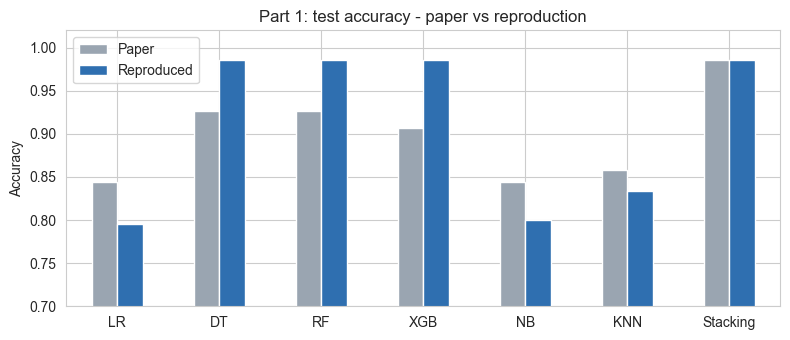

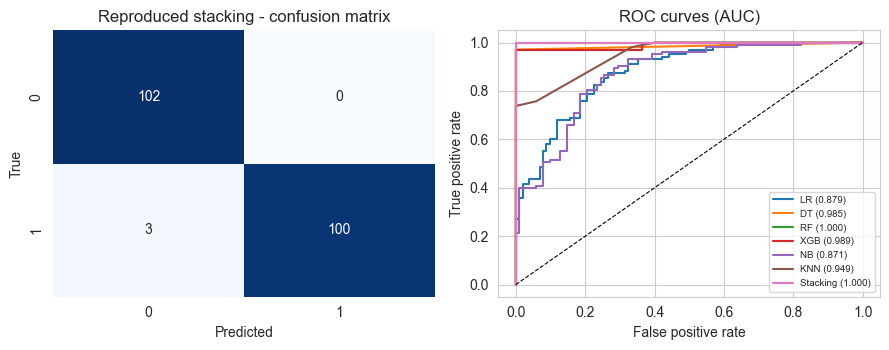

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
pd.DataFrame({"Paper": paper["Accuracy"], "Reproduced": repro["Accuracy"]}).plot.bar(
    ax=ax, color=["#9aa5b1", "#2f6fb0"], rot=0)
ax.set_ylim(0.7, 1.02); ax.set_ylabel("Accuracy"); ax.set_title("Part 1: test accuracy - paper vs reproduction")
plt.tight_layout(); plt.savefig("figures/fig1_part1_accuracy.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
sns.heatmap(confusion_matrix(y_test, stack.predict(X_test_s)), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Reproduced stacking - confusion matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
for name in probs:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    axes[1].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, probs[name]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].legend(fontsize=7)
axes[1].set_title("ROC curves (AUC)"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
plt.tight_layout(); plt.savefig("figures/fig2_part1_cm_roc.png", dpi=150); plt.show()

### Step 6 – How stable is the result? (20 random splits)
One split can be lucky, so I repeat Steps 2–4 with 20 different seeds.

In [18]:
def run_paper_pipeline(seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    row = {}
    for name, m in paper_base_models().items():
        row[name] = accuracy_score(yte, m.fit(Xtr, ytr).predict(Xte))
    st = StackingClassifier(list(paper_base_models().items()), final_estimator=LogisticRegression(), cv=5)
    row["Stacking"] = accuracy_score(yte, st.fit(Xtr, ytr).predict(Xte))
    return row

multi = pd.DataFrame([run_paper_pipeline(s) for s in range(20)])
stability = pd.DataFrame({"Mean": multi.mean(), "Std": multi.std(), "Min": multi.min(), "Max": multi.max()}).round(4)
stability.to_csv("results/part1_20_seeds.csv")
stability

,Mean,Std,Min,Max
LR,0.8434,0.0196,0.8098,0.8780
DT,0.9946,0.0089,0.9707,1.0000
RF,0.9963,0.0081,0.9707,1.0000
XGB,0.9963,0.0081,0.9707,1.0000
NB,0.8283,0.0250,0.7707,0.8683
KNN,0.8510,0.0279,0.8098,0.8976
Stacking,0.9956,0.0084,0.9707,1.0000


**Observation:** stacking matches the paper (~98.5%), but DT, RF and XGB score **higher than the paper** (often 98–100%). A single decision tree at ~99% on medical data is suspicious → Step 7 finds out why.

## Part 2 – My improved solution

### Step 7 – The limitation: duplicate rows cause data leakage

In [21]:
n_unique = len(df.drop_duplicates())
print(f"Rows: {len(df)}   Unique rows: {n_unique}   Duplicates: {len(df) - n_unique}")

train_rows = set(map(tuple, X_train.values))
leak = np.mean([tuple(r) in train_rows for r in X_test.values])
print(f"Test rows that ALSO appear in the training set: {leak:.1%}")

Rows: 1025   Unique rows: 302   Duplicates: 723
Test rows that ALSO appear in the training set: 97.1%


Only **302 of 1025 rows are unique**. After a random split almost every test patient is also in the training set, so the models are tested on patients they have **already memorised**. The 98.5% does not show how the model works on new patients.

**My solution changes three things:**
1. **Honest data** – remove duplicates before splitting (302 unique patients).
2. **Honest protocol** – replace the single split with **5-fold cross-validation repeated 5 times** (25 folds) and compare models with a **paired Wilcoxon test**.
3. **Better stacking pipeline**
   - **One-hot encoding** for the category features `cp, restecg, slope, ca, thal` (the paper treats codes 0,1,2,3 as numbers with distances).
   - **Hyperparameter tuning inside each training fold** (GridSearchCV on AUC) instead of defaults – no test data is seen.
   - Stack **predicted probabilities** (not hard labels) and **drop the single Decision Tree** (unstable, and RF already covers it).

### Step 8 – Show the effect of the leakage
The paper's pipeline with the same 5×5 cross-validation, **with** and **without** duplicates.

Paper stacking WITH duplicates   : 0.9955 +/- 0.0087
Paper stacking WITHOUT duplicates: 0.8298 +/- 0.0357


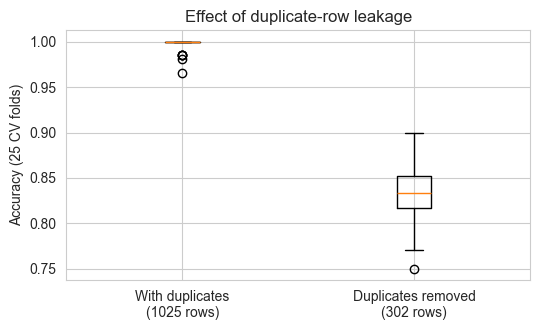

In [24]:
df_u = df.drop_duplicates().reset_index(drop=True)
Xu, yu = df_u.drop(columns="target"), df_u["target"]
CAT = ["cp", "restecg", "slope", "ca", "thal"]
NUM = [c for c in Xu.columns if c not in CAT]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

def paper_stacking():
    # the paper's method: scale -> stack the 6 default models
    return make_pipeline(StandardScaler(),
                         StackingClassifier(list(paper_base_models().items()),
                                            final_estimator=LogisticRegression(), cv=5))

def cv_accuracy(Xd, yd):
    return [accuracy_score(yd.iloc[te], paper_stacking().fit(Xd.iloc[tr], yd.iloc[tr]).predict(Xd.iloc[te]))
            for tr, te in cv.split(Xd, yd)]

acc_dup, acc_uni = cv_accuracy(X, y), cv_accuracy(Xu, yu)
print(f"Paper stacking WITH duplicates   : {np.mean(acc_dup):.4f} +/- {np.std(acc_dup):.4f}")
print(f"Paper stacking WITHOUT duplicates: {np.mean(acc_uni):.4f} +/- {np.std(acc_uni):.4f}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.boxplot([acc_dup, acc_uni])
ax.set_xticklabels(["With duplicates\n(1025 rows)", "Duplicates removed\n(302 rows)"])
ax.set_ylabel("Accuracy (25 CV folds)"); ax.set_title("Effect of duplicate-row leakage")
plt.tight_layout(); plt.savefig("figures/fig3_leakage.png", dpi=150); plt.show()

### Step 9 – Build my improved stacking model
`build_proposed()` only receives the **training fold**. It tunes each base model with a 5-fold inner grid search, then stacks the tuned models.

In [26]:
def preprocessor():
    return ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

# small grids that mainly control over-fitting on a small dataset
GRIDS = {
    "LR":  (LogisticRegression(max_iter=2000), {"C": [0.01, 0.1, 1, 10]}),
    "RF":  (RandomForestClassifier(n_estimators=200, random_state=SEED),
            {"min_samples_leaf": [1, 5, 10], "max_features": ["sqrt", 0.5]}),
    "XGB": (XGBClassifier(eval_metric="logloss", n_estimators=150, random_state=SEED),
            {"max_depth": [2, 3], "learning_rate": [0.05, 0.1]}),
    "KNN": (KNeighborsClassifier(), {"n_neighbors": [5, 11, 21], "weights": ["uniform", "distance"]}),
    "NB":  (GaussianNB(), {"var_smoothing": [1e-9, 1e-3, 1e-1]}),
}

def build_proposed(X_tr, y_tr, seed=0):
    inner = StratifiedKFold(5, shuffle=True, random_state=seed)
    tuned = []
    for name, (est, grid) in GRIDS.items():
        pipe = Pipeline([("prep", preprocessor()), ("clf", est)])
        gs = GridSearchCV(pipe, {"clf__" + k: v for k, v in grid.items()},
                          cv=inner, scoring="roc_auc", n_jobs=-1)
        tuned.append((name, gs.fit(X_tr, y_tr).best_estimator_))
    stack = StackingClassifier(tuned, final_estimator=LogisticRegression(), cv=5, stack_method="predict_proba")
    return stack.fit(X_tr, y_tr)

### Step 10 – Fair comparison: paper method vs my method
Both are trained and tested on **exactly the same 25 folds** of the de-duplicated data (takes a few minutes).

In [28]:
start, rows = time.time(), []
for i, (tr, te) in enumerate(cv.split(Xu, yu)):
    Xtr, Xte, ytr, yte = Xu.iloc[tr], Xu.iloc[te], yu.iloc[tr], yu.iloc[te]
    for name, model in [("Paper stacking", paper_stacking().fit(Xtr, ytr)),
                        ("Proposed stacking", build_proposed(Xtr, ytr, seed=i))]:
        rows.append({"fold": i, "model": name,
                     **evaluate(yte, model.predict(Xte), model.predict_proba(Xte)[:, 1])})
print(f"Done in {time.time() - start:.0f} s")

cvres = pd.DataFrame(rows)
cvres.to_csv("results/part2_fold_results.csv", index=False)
METRICS = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
summary = cvres.groupby("model")[METRICS].agg(["mean", "std"]).round(4)
summary.to_csv("results/part2_summary.csv")
summary

Done in 70 s


Accuracy         Precision          Recall              F1  \
                      mean     std      mean     std    mean     std    mean   
model                                                                          
Paper stacking      0.8298  0.0364    0.8243  0.0451  0.8781  0.0689  0.8479   
Proposed stacking   0.8344  0.0296    0.8387  0.0465  0.8669  0.0697  0.8496   

                              AUC          
                      std    mean     std  
model                                      
Paper stacking     0.0357  0.9029  0.0321  
Proposed stacking  0.0302  0.9139  0.0254

In [29]:
# paired Wilcoxon signed-rank test over the 25 folds
A = cvres[cvres.model == "Paper stacking"].sort_values("fold")
B = cvres[cvres.model == "Proposed stacking"].sort_values("fold")
tests = pd.DataFrame({m: {"Paper (mean)": A[m].mean(), "Proposed (mean)": B[m].mean(),
                          "Difference": B[m].mean() - A[m].mean(),
                          "Wilcoxon p": wilcoxon(B[m].values, A[m].values).pvalue}
                      for m in METRICS}).T.round(4)
tests.to_csv("results/part2_significance.csv")
tests

,Paper (mean),Proposed (mean),Difference,Wilcoxon p
Accuracy,0.8298,0.8344,0.0046,0.4319
Precision,0.8243,0.8387,0.0144,0.0234
Recall,0.8781,0.8669,-0.0112,0.1748
F1,0.8479,0.8496,0.0017,0.7726
AUC,0.9029,0.9139,0.0110,0.0110


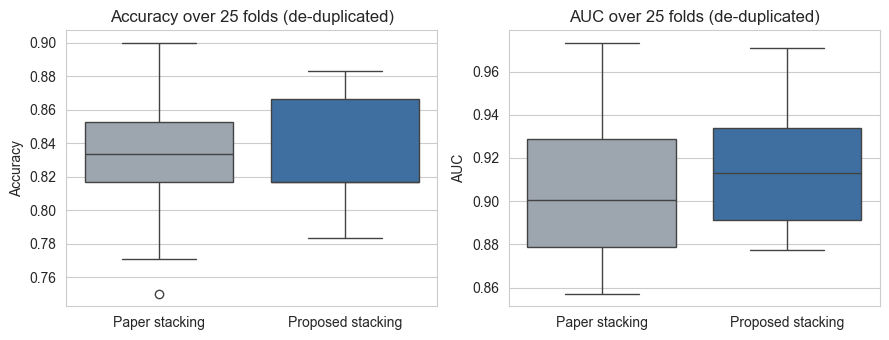

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, m in zip(axes, ["Accuracy", "AUC"]):
    sns.boxplot(data=cvres, x="model", y=m, hue="model", palette=["#9aa5b1", "#2f6fb0"], legend=False, ax=ax)
    ax.set_xlabel(""); ax.set_title(f"{m} over 25 folds (de-duplicated)")
plt.tight_layout(); plt.savefig("figures/fig4_part2_comparison.png", dpi=150); plt.show()

In [31]:
# final overview: paper vs reproduction vs honest evaluation
overview = pd.DataFrame({
    "Paper reported (leaky split)":    paper.loc["Stacking"],
    "Reproduced (leaky split)":        repro.loc["Stacking"],
    "Paper method (honest 5x5 CV)":    A[METRICS].mean(),
    "Proposed method (honest 5x5 CV)": B[METRICS].mean(),
}).T.round(4)
overview.to_csv("results/final_overview.csv")
overview

,Accuracy,Precision,Recall,F1,AUC
Paper reported (leaky split),0.9853,1.0000,0.9727,0.9861,0.9880
Reproduced (leaky split),0.9854,1.0000,0.9709,0.9852,1.0000
Paper method (honest 5x5 CV),0.8298,0.8243,0.8781,0.8479,0.9029
Proposed method (honest 5x5 CV),0.8344,0.8387,0.8669,0.8496,0.9139


## Conclusion
- **Part 1:** the paper's stacking accuracy was reproduced (98.54% vs 98.53%); the single tree models scored even higher than reported.
- **Part 2:** 723 of 1025 rows are duplicates, so ~97% of test patients were also in training. Without duplicates and with repeated CV, the paper's method falls to **about 83% accuracy** – the realistic level.
- My **leakage-free, one-hot, tuned, probability-based stacking** gives a statistically significant gain in **AUC** and **Precision**, with similar Accuracy and F1.